**DATA Loading and First Look**

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
df=pd.read_csv("project_dataset_heart_diesese.csv", sep=';')

# The head function gives the first five columns.
df.head()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,48,0
1,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,46,0
2,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,66,0
3,1,1,0,1,0,0,1,1,1,0,1,1,0,1,1,1,1,60,1
4,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,69,0


In [3]:
# The Shape function gives the number of rows and columns.
df.shape

(70000, 19)

In [4]:
# The Info function gives the data types.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Chest_Pain           70000 non-null  int64
 1   Shortness_of_Breath  70000 non-null  int64
 2   Fatigue              70000 non-null  int64
 3   Palpitations         70000 non-null  int64
 4   Dizziness            70000 non-null  int64
 5   Swelling             70000 non-null  int64
 6   Pain_Arms_Jaw_Back   70000 non-null  int64
 7   Cold_Sweats_Nausea   70000 non-null  int64
 8   High_BP              70000 non-null  int64
 9   High_Cholesterol     70000 non-null  int64
 10  Diabetes             70000 non-null  int64
 11  Smoking              70000 non-null  int64
 12  Obesity              70000 non-null  int64
 13  Sedentary_Lifestyle  70000 non-null  int64
 14  Family_History       70000 non-null  int64
 15  Chronic_Stress       70000 non-null  int64
 16  Gender               70000 non-nu

**Exploratory Data Analysis (EDA)**

In [5]:
#The describe function gives statical summery of the data.
df.describe

<bound method NDFrame.describe of        Chest_Pain  Shortness_of_Breath  Fatigue  Palpitations  Dizziness  \
0               0                    0        0             1          0   
1               0                    1        0             1          0   
2               1                    0        0             1          0   
3               1                    1        0             1          0   
4               0                    0        1             0          1   
...           ...                  ...      ...           ...        ...   
69995           0                    0        1             0          0   
69996           1                    1        1             0          1   
69997           0                    0        0             0          0   
69998           1                    1        0             1          1   
69999           1                    1        1             1          1   

       Swelling  Pain_Arms_Jaw_Back  Cold_Sweats_Naus

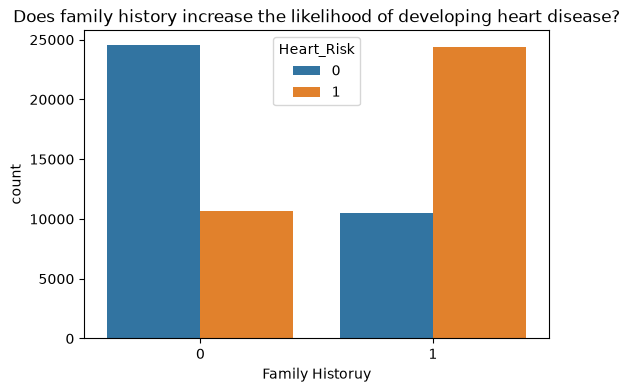

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='Family_History',hue='Heart_Risk')
plt.title('Does family history increase the likelihood of developing heart disease?')
plt.xlabel('Family Historuy')
plt.ylabel('count')
plt.show()

#This diagram illustrates the relationship between family history and the likelihood of developing heart disease.
#In some cases, family history may contribute to the development of heart disease.

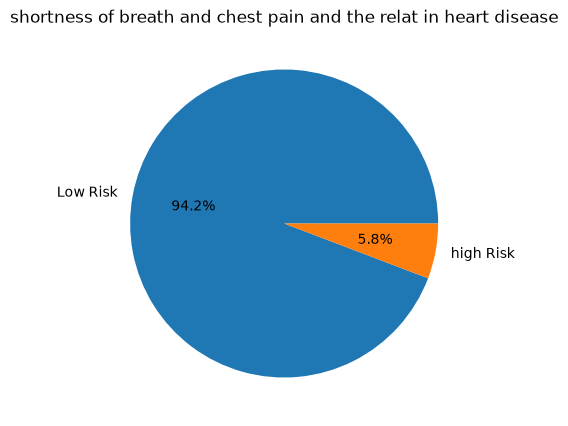

In [7]:

symptoms=df[(df['Chest_Pain']==1)&(df['Shortness_of_Breath']==1)]
risk_counts= symptoms['Heart_Risk'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(risk_counts,labels=['Low Risk','high Risk'],autopct='%1.1f%%')
plt.title('shortness of breath and chest pain and the relat in heart disease')
plt.show()
#The diagram illustrates the incidence of heart disease based on exposure to chest pain and shortness of breath.
#Those who suffer from shortness of breath and chest pain are not necessarily at risk of heart disease.

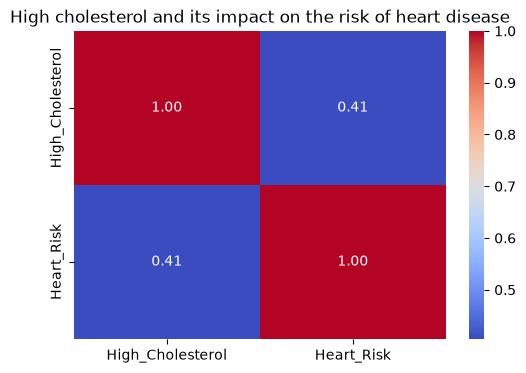

In [8]:
plt.figure(figsize=(6,4))
corr =df[['High_Cholesterol','Heart_Risk']].corr()
sns.heatmap( corr, annot=True,cmap='coolwarm',fmt='.2f')
plt.title('High cholesterol and its impact on the risk of heart disease')
plt.show()
#The diagram illustrates the relationship between high cholesterol and heart disease.
#Higher cholesterol levels increase the likelihood of developing heart disease, but the relationship is neither strong nor weak.

**DATA Cleaning**

In [9]:
#missing values 
print(df.isnull().sum().sum())


0


In [10]:
#Duplicate Values
print(df.duplicated().sum())

6245


In [11]:
#Delete duplicated values 
df=df.drop_duplicates()

In [12]:
print(df.duplicated().sum())

0


In [13]:
Q1=df['Age'].quantile(0.25)
Q3=df['Age'].quantile(0.75)
IQR = Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
outliers=df[(df['Age']<lower)| (df['Age']>upper)]
print('Num of outlier:', len (outliers))


Num of outlier: 0


**Preprocessing**

**Encoding:**

In [14]:

print(df.dtypes)
#all featuer are represented numerically.

Chest_Pain             int64
Shortness_of_Breath    int64
Fatigue                int64
Palpitations           int64
Dizziness              int64
Swelling               int64
Pain_Arms_Jaw_Back     int64
Cold_Sweats_Nausea     int64
High_BP                int64
High_Cholesterol       int64
Diabetes               int64
Smoking                int64
Obesity                int64
Sedentary_Lifestyle    int64
Family_History         int64
Chronic_Stress         int64
Gender                 int64
Age                    int64
Heart_Risk             int64
dtype: object


**Scaling**:

In [15]:
#Defining the objective and feature
x= df.drop('Heart_Risk',axis=1)
y= df['Heart_Risk']

In [16]:
#Split the data
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)

In [17]:
#Scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.fit_transform(X_test)

#fit_transform calculate the mean and standerd diveion from train data.
#transform هt works on the same data as the test to prevent data leakage.

In [18]:
# To make sure that the Scaling is work.
print(X_train_scaled[:5])


[[-0.98822709 -0.9916823  -0.98989499  1.01449609 -0.99390143 -0.9905163
   1.00735984 -0.99378451 -0.98764591 -0.990594   -0.99546164  1.00231623
  -0.98768464  0.99851103 -0.99141012 -0.99090482 -1.09343913  0.46418507]
 [-0.98822709 -0.9916823  -0.98989499 -0.98571105 -0.99390143  1.0095745
  -0.99269393 -0.99378451 -0.98764591  1.00949532 -0.99546164  1.00231623
   1.01246892  0.99851103  1.00866431 -0.99090482  0.91454565 -0.38839717]
 [-0.98822709  1.00838746 -0.98989499 -0.98571105 -0.99390143 -0.9905163
   1.00735984 -0.99378451  1.01250862  1.00949532 -0.99546164 -0.99768913
   1.01246892 -1.00149119 -0.99141012  1.00917866 -1.09343913  0.34238761]
 [ 1.01191317 -0.9916823   1.01020817  1.01449609  1.00613599  1.0095745
   1.00735984 -0.99378451 -0.98764591  1.00949532  1.00455906  1.00231623
   1.01246892  0.99851103  1.00866431 -0.99090482  0.91454565  1.01227366]
 [-0.98822709 -0.9916823   1.01020817 -0.98571105  1.00613599 -0.9905163
   1.00735984  1.00625436 -0.98764591  

**PCA**

In [19]:
#Applying PCA to the data to determine the variance ratio
from sklearn.decomposition import PCA
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.fit_transform(X_test_scaled)
print(pca.explained_variance_ratio_)

[0.27078913 0.05168287 0.05008647 0.0490822  0.04856319 0.04816336
 0.04720002 0.0469241  0.04623808 0.04447086 0.03916928 0.03784368
 0.03776003 0.03727149 0.03702983 0.03651374 0.03628551 0.03492615]


In [20]:
#Understanding cumulative variance
import numpy as np 
cumulative_variance= np.cumsum(pca.explained_variance_ratio_)
print ( cumulative_variance)

[0.27078913 0.32247201 0.37255848 0.42164068 0.47020386 0.51836723
 0.56556725 0.61249134 0.65872942 0.70320029 0.74236957 0.78021325
 0.81797328 0.85524477 0.8922746  0.92878834 0.96507385 1.        ]


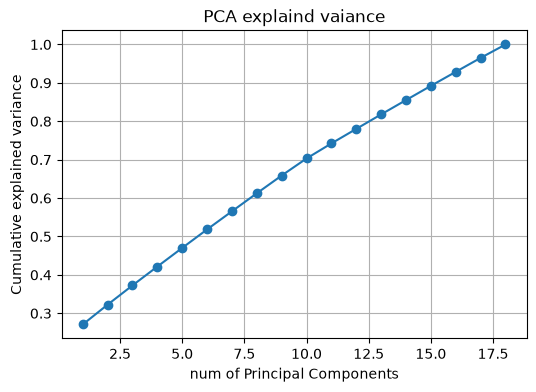

In [21]:
plt.figure(figsize=(6,4))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o')
plt.xlabel('')
plt.xlabel('num of Principal Components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA explaind vaiance')
plt.grid(True)
plt.show()

In [22]:
pca =PCA(n_components=0.95)
X_train_pca= pca.fit_transform(X_train_scaled)
X_test_pca= pca.transform(X_test_scaled)
print("NUM of componants:",pca.n_components_)


NUM of componants: 17


The method of operation PCA We tried to preserve the essential parts that contain more variance in the data, and remove the non-essential parts with less variance.

**Modeling**

Here is two classifiaction models that we are trained by using preprocessed data set.

**Random Forest:**

In [32]:
from sklearn.ensemble import RandomForestClassifier
RF= RandomForestClassifier(random_state=42)
RF.fit(X_train_scaled,y_train)
y_pred_RF= RF.predict(X_test_scaled)


**SVM**:

In [34]:
from sklearn.svm import SVC
svm = SVC(random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

**Evaluation**

The Random Forest and Support Vector Machine (SVM) were evaluated using Accuracy , Precision , Recall and F1-score and Confusion Matrix.

In [28]:
from sklearn.metrics import(
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)


Evaluate Random Forest 


In [33]:
print("Accuracy:", accuracy_score(y_test, y_pred_RF))
print("Precision:", precision_score(y_test, y_pred_RF))
print("Recall:", recall_score(y_test, y_pred_RF))
print("F1-score:", f1_score(y_test, y_pred_RF))

Accuracy: 0.9917653517371187
Precision: 0.9908053265694357
Recall: 0.9925361283150707
F1-score: 0.9916699722332408


Evaluate SVM

In [35]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1-score:", f1_score(y_test, y_pred_svm))

Accuracy: 0.9915300760724649
Precision: 0.9914244878513578
Recall: 0.9914244878513578
F1-score: 0.9914244878513578


After evaluating both models, we found that the random forest model achieved better results compared to the SVM model, demonstrating high accuracy and high recall. It also achieved a higher score of F1.

**Conclusion**

Through this project, I learned how to train a model, test it, obtain metrics, and compare them to find the best one. I found that the random forest model was the best in terms of results because it yielded better results compared to the other model and made the data easier to understand. To further develop this project, I could test other models and see how the results would differ or be similar.